<a href="https://colab.research.google.com/github/EgorMatveev26/SOTA/blob/main/lab5SOTA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторная работа №5: CLIP: zero-shot-классификация и мультимодальный поиск

**Версия:** студенческая  
**Курс:** «Современное компьютерное зрение»

> Сначала выполните notebook в режиме `FAST_DEV_RUN=True`, затем запускайте полный эксперимент. Сохраняйте метрики и checkpoints в `artifacts/`.


## Цели обучения

После работы студент должен уметь:

- Сравнить prompt templates в zero-shot classification.
- Построить text-to-image retrieval.
- Дообучить projection head и оценить Recall@K.


## Теоретическая часть

CLIP обучает image encoder и text encoder в общем нормированном пространстве. Zero-shot logits пропорциональны cosine similarity между изображением и текстовыми шаблонами классов.

![CLIP](https://raw.githubusercontent.com/openai/CLIP/main/CLIP.png)


### Математическая постановка

$$s(x,t)=\frac{f_I(x)^\top f_T(t)}{\|f_I(x)\|\|f_T(t)\|},\qquad p(c\mid x)=\operatorname{softmax}(s(x,t_c)/\tau).$$
Для retrieval используются Recall@K и median rank.


### Материалы

- [OpenCLIP](https://github.com/mlfoundations/open_clip)
- [CLIP paper](https://arxiv.org/abs/2103.00020)

Ссылки даны как дополнительный материал. При изменении API сверяйтесь с актуальной официальной документацией и фиксируйте версии зависимостей.


## Практическое задание

1. Сравнить prompt templates в zero-shot classification.
2. Построить text-to-image retrieval.
3. Дообучить projection head и оценить Recall@K.

**Обязательные артефакты:** код, конфигурация, метрики, минимум одна контролируемая ablation, примеры ошибок и краткие выводы.


### Профиль вычислений

- **Основной режим:** OpenCLIP ViT-B-32 frozen/малый projection head.
- **Ограничение данных:** CIFAR-10 или до 5 000 пар.
- **Fallback:** CPU на 500 объектах.
- Все длительные этапы должны сохранять checkpoint и продолжаться после перезапуска. Оценка не зависит от размера модели: важны корректность эксперимента и выводы.


**Оценивание.** Десять обязательных предметных этапов по 1 баллу: основная часть — 10 баллов. Творческий бонус — отдельно 1 балл, не заменяет обязательные этапы. Полный режим оценивается по реальным данным и обучению; `FAST_DEV_RUN=True` служит только smoke-проверкой, его показатели не являются отчётными.


## Реализация


In [ ]:
# Базовое воспроизводимое окружение
from pathlib import Path
import json, os, random, time
import numpy as np

SEED = 42
FAST_DEV_RUN = False  # True — только проверка связности на уменьшенной выборке; не отчётный результат
# монтируем Drive и определяем ARTIFACTS
try:
    from google.colab import drive
    drive.mount("/content/drive")
    ARTIFACTS = Path("/content/drive/MyDrive/cv_lab5_artifacts")
except ImportError:
    # локальный запуск вне Colab
    ARTIFACTS = Path(os.getenv("CV_ARTIFACTS", "artifacts"))
ARTIFACTS.mkdir(parents=True, exist_ok=True)
random.seed(SEED); np.random.seed(SEED)
try:
    import torch
    torch.manual_seed(SEED)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
    DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
except ImportError:
    torch = None
    DEVICE = "cpu"
# Датасеты курса лежат в общем каталоге <корень курса>/data:
# notebook выполняется из labs/lab_XX_*/, поэтому корень курса — cwd.parent.parent.
# Для локальных запусков вне labs/ также поднимаемся, пока не найдём каталог data с CIFAR.
_CANDIDATES = [Path.cwd().parent.parent / "data", Path.cwd().parent / "data", Path.cwd() / "data"]
DATA_ROOT = Path(os.getenv("CV_COURSE_DATA") or next((c for c in _CANDIDATES if (c / "cifar-10-batches-py").exists()), _CANDIDATES[0]))
DATA_ROOT.mkdir(parents=True, exist_ok=True)
print({"device": DEVICE, "fast_dev_run": FAST_DEV_RUN, "data_root": str(DATA_ROOT)})


Mounted at /content/drive
{'device': 'cpu', 'fast_dev_run': False, 'data_root': '/data'}


In [ ]:
def check(condition, message):
    """Мини-проверка в стиле YAAM: молчит, если всё хорошо; печатает, если найдена проблема."""
    if condition:
        print(f"✔ {message}")
    else:
        print(f"✘ ВНИМАНИЕ: {message}")

### Данные и предобученный CLIP

*Вес: 1 балл.*

**Постановка.** Индекс поиска и обучающие пары должны состоять из разных изображений.

Выполните следующие действия:
1. Загрузите CIFAR-10 train/test и OpenCLIP ViT-B-32.
2. Определите список классов и независимый test-загрузчик.

**Результат.** Объекты model, train_pairs, ds, classes, loader.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [ ]:
!pip install -q open_clip_torch

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 19.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.8/44.8 kB 1.8 MB/s eta 0:00:00


In [ ]:
import torch
import open_clip
import torchvision
from torchvision import transforms
from torch.utils.data import DataLoader, Dataset
from PIL import Image
import numpy as np
import json
import os

# загрузка CLIP (ViT-B-32)
model, _, preprocess = open_clip.create_model_and_transforms('ViT-B-32', pretrained='laion2b_s34b_b79k')
tokenizer = open_clip.get_tokenizer('ViT-B-32')
model = model.to(DEVICE)
model.eval()

# классы CIFAR-10
classes = ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']

# Трансформация для CLIP (встроенный preprocess)
# загружаем CIFAR-10 (train для проекции, test для оценки)
train_ds = torchvision.datasets.CIFAR10(root=str(DATA_ROOT), train=True, download=True, transform=preprocess)
test_ds = torchvision.datasets.CIFAR10(root=str(DATA_ROOT), train=False, download=True, transform=preprocess)

train_subset = torch.utils.data.Subset(train_ds, range(min(1000, len(train_ds))))
test_subset = torch.utils.data.Subset(test_ds, range(min(500, len(test_ds))))

train_loader = DataLoader(train_subset, batch_size=32, shuffle=True, num_workers=0)
test_loader = DataLoader(test_subset, batch_size=32, shuffle=False, num_workers=0)

print(f"Train: {len(train_subset)}, Test: {len(test_subset)}")


open_clip_model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

open_clip_model.safetensors: downloading bytes:           |  0.00B            

100%|██████████| 170M/170M [46:19<00:00, 61.3kB/s]


Train: 1000, Test: 500


Скачали нейросеть CLIP, которая умеет сравнивать картинки и текст, и датасет CIFAR-10. Взяли 1000 картинок для обучения и 500 для проверки.

### Текстовые прототипы классов

*Вес: 1 балл.*

**Постановка.** Нормализация эмбеддингов превращает скалярное произведение в cosine similarity.

Выполните следующие действия:
1. Создайте несколько шаблонов класса.
2. Закодируйте и нормируйте текстовые прототипы.

**Результат.** templates и функция text_prototypes.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [ ]:
templates = [
    "a photo of a {}.",
    "a blurry photo of a {}.",
    "a photo of a small {}.",
    "a photo of a large {}.",
    "a photo of the {}.",
]

def text_prototypes(class_names, template_list, tokenizer, model):
    protos = {}
    with torch.no_grad():
        for name in class_names:
            texts = [t.format(name) for t in template_list]
            tokens = tokenizer(texts).to(DEVICE)
            feats = model.encode_text(tokens)
            feats = feats / feats.norm(dim=-1, keepdim=True)
            protos[name] = feats.mean(dim=0)  # усредняем по шаблонам
            protos[name] = protos[name] / protos[name].norm()
    return protos

protos = text_prototypes(classes, templates, tokenizer, model)
print(f"Созданы прототипы для {len(protos)} классов")


Созданы прототипы для 10 классов


Придумали 5 разных фраз для каждого класса, прогнали их через нейросеть и усреднили. Получили эталонные текстовые описания для каждого класса.

### Zero-shot классификация

*Вес: 1 балл.*

**Постановка.** Подбор словесного шаблона влияет на прогноз без дополнительного обучения.

Выполните следующие действия:
1. Для каждого заранее заданного шаблона предскажите test-классы по сходству.
2. Зафиксируйте accuracy всех шаблонов без выбора лучшей модели по test.

**Результат.** zero_shot.json с фактической точностью шаблонов.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [ ]:
from sklearn.metrics import accuracy_score

zero_shot_results = {}
all_preds = []
all_labels = []

with torch.no_grad():
    for imgs, labels in test_loader:
        imgs = imgs.to(DEVICE)
        img_feats = model.encode_image(imgs)
        img_feats = img_feats / img_feats.norm(dim=-1, keepdim=True)
        all_labels.extend(labels.numpy())
        all_preds.append(img_feats.cpu())

all_preds = torch.cat(all_preds, dim=0)
all_labels = np.array(all_labels)

for t_idx, template in enumerate(templates):
    protos_t = {}
    with torch.no_grad():
        for name in classes:
            text = template.format(name)
            tokens = tokenizer([text]).to(DEVICE)
            feat = model.encode_text(tokens)
            feat = feat / feat.norm(dim=-1, keepdim=True)
            protos_t[name] = feat.squeeze(0)

    proto_matrix = torch.stack([protos_t[c] for c in classes])  # (10, 512)
    logits = all_preds @ proto_matrix.T # (N, 10)
    preds = logits.argmax(dim=-1).numpy()
    acc = accuracy_score(all_labels, preds)
    zero_shot_results[template] = float(acc)
    print(f"Template: '{template}' -> Accuracy: {acc:.4f}")

with open(ARTIFACTS / "zero_shot.json", "w") as f:
    json.dump(zero_shot_results, f, indent=2)

print("\nЛучший шаблон:", max(zero_shot_results, key=zero_shot_results.get))


Template: 'a photo of a {}.' -> Accuracy: 0.9360
Template: 'a blurry photo of a {}.' -> Accuracy: 0.9280
Template: 'a photo of a small {}.' -> Accuracy: 0.9220
Template: 'a photo of a large {}.' -> Accuracy: 0.9120
Template: 'a photo of the {}.' -> Accuracy: 0.9280

Лучший шаблон: a photo of a {}.


Для каждой из 5 фраз проверили, насколько хорошо модель угадывает класс картинки. Получили, что лучшая фраза a photo of a {}

### Векторный индекс изображений

*Вес: 1 балл.*

**Постановка.** Текстовый поиск опирается на сохранённые признаки реальных изображений.

Выполните следующие действия:
1. Извлеките нормированные эмбеддинги test и метки.
2. Вычислите top-10 для текстового запроса.

**Результат.** clip_index.pt и retrieval.json с индексами test.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


Запрос: 'a photo of a cat', top-10 классы: [3 3 3 3 3 3 3 3 3 3]
top-10 CIFAR test indices: [245, 279, 256, 336, 320, 187, 432, 103, 397, 46]


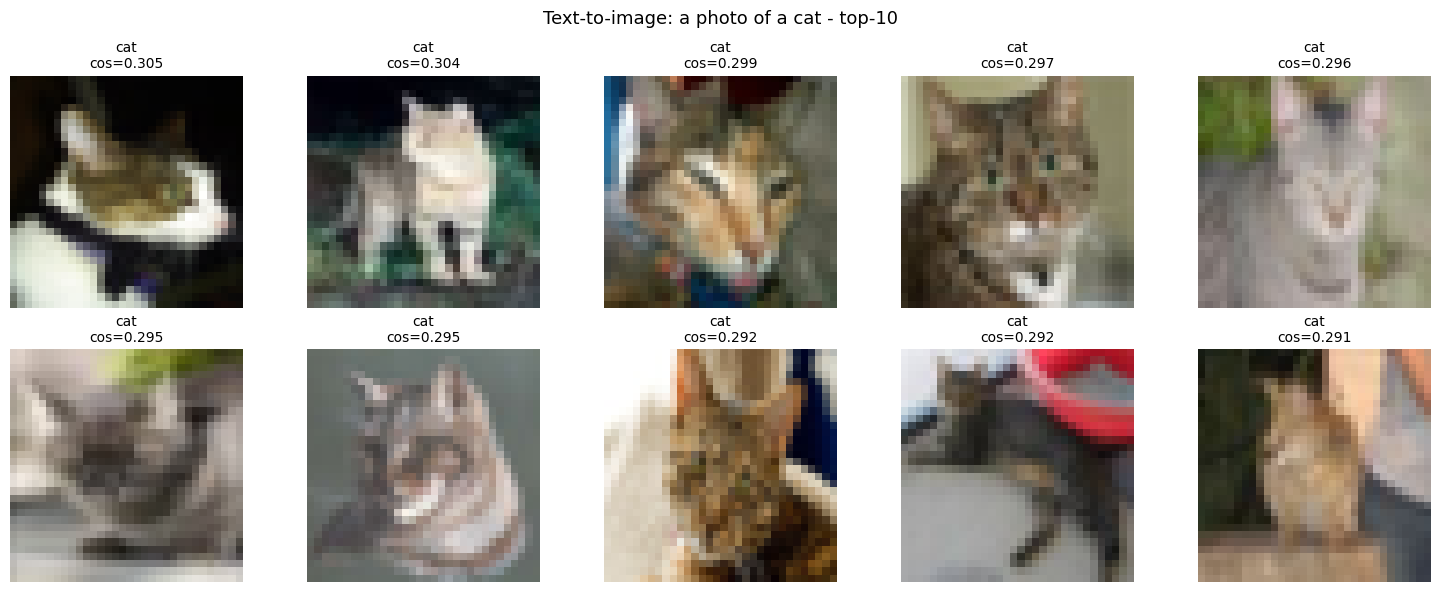

In [ ]:
#извлекаем эмбеддинги test
test_embeddings = []
test_labels = []

with torch.no_grad():
    for imgs, labels in test_loader:
        imgs = imgs.to(DEVICE)
        feats = model.encode_image(imgs)
        feats = feats / feats.norm(dim=-1, keepdim=True)
        test_embeddings.append(feats.cpu())
        test_labels.extend(labels.numpy())

test_embeddings = torch.cat(test_embeddings, dim=0) # (N_test, 512), L2-normalized
test_labels = np.array(test_labels)
test_indices = list(test_subset.indices) # реальные индексы в CIFAR test

torch.save({
    "embeddings": test_embeddings,
    "labels": test_labels,
    "indices": test_indices,
}, ARTIFACTS / "clip_index.pt")

# текстовый запрос
query_text = "a photo of a cat"
tokens = tokenizer([query_text]).to(DEVICE)
with torch.no_grad():
    text_feat = model.encode_text(tokens)
    text_feat = text_feat / text_feat.norm(dim=-1, keepdim=True)

sims = (test_embeddings @ text_feat.cpu().T).squeeze()
top10 = torch.argsort(sims, descending=True)[:10].numpy()

retrieval_results = {
    "query": query_text,
    "top10_positions": top10.tolist(),
    "top10_test_indices": [int(test_indices[i]) for i in top10],
    "top10_labels": test_labels[top10].tolist(),
    "top10_cosine": [float(sims[i]) for i in top10],
}
with open(ARTIFACTS / "retrieval.json", "w") as f:
    json.dump(retrieval_results, f, indent=2)

print(f"Запрос: '{query_text}', top-10 классы: {test_labels[top10]}")
print(f"top-10 CIFAR test indices: {[int(test_indices[i]) for i in top10]}")

import matplotlib.pyplot as plt

# сырой CIFAR test без CLIP-трансформаций для показа картинок
raw_test = torchvision.datasets.CIFAR10(
    root=str(DATA_ROOT), train=False, download=True, transform=None
)


def show_top10(test_idx_list, labels_list, cosines, title, fname, ncols=5):
    n = len(test_idx_list)
    nrows = (n + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(3 * ncols, 3 * nrows))
    axes = np.array(axes).ravel()

    for ax, real_idx, lbl, cos in zip(axes, test_idx_list, labels_list, cosines):
        img, _ = raw_test[int(real_idx)]
        ax.imshow(img)
        ax.axis("off")
        ax.set_title(f"{classes[int(lbl)]}\ncos={cos:.3f}", fontsize=10)

    for ax in axes[n:]:
        ax.axis("off")

    fig.suptitle(title, fontsize=13)
    plt.tight_layout()
    plt.savefig(ARTIFACTS / fname, dpi=120, bbox_inches="tight")
    plt.show()


show_top10(
    retrieval_results["top10_test_indices"],
    retrieval_results["top10_labels"],
    retrieval_results["top10_cosine"],
    title=f"Text-to-image: {retrieval_results['query']} - top-10",
    fname="retrieval_top10.png",
)


Прогнали все 500 картинок через нейросеть и сохранили их векторы. Потом задали текстовый запрос a photo of a cat и нашли 10 самых похожих картинок. Получили 10 котов, все правильно.

### Релевантность поиска по классам

*Вес: 1 балл.*

**Постановка.** Precision@10 и recall@10 требуют фиксированного определения релевантности.

Выполните следующие действия:
1. Задайте релевантность как совпадение с классом запроса.
2. Вычислите метрики поиска для каждого класса.

**Результат.** retrieval_report.json с фактическими значениями.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [ ]:
def ranking_metrics(sims, labels, class_idx, K=10):
    order = torch.argsort(sims, descending=True).numpy()
    topK = order[:K]
    rel_topK = (labels[topK] == class_idx).astype(int)

    precision = rel_topK.mean()
    total_rel = int((labels == class_idx).sum())
    recall = rel_topK.sum() / max(1, total_rel)  # потолок = K / total_rel

    # AP@K
    hits, ap = 0, 0.0
    for i, r in enumerate(rel_topK, start=1):
        if r:
            hits += 1
            ap += hits / i
    ap = ap / max(1, min(K, total_rel))

    # median rank первого релевантного
    rel_positions = np.where(labels[order] == class_idx)[0]
    first_rank = int(rel_positions[0]) + 1 if len(rel_positions) else len(labels) + 1

    return precision, recall, ap, first_rank, total_rel


report = {}
first_ranks = []

for class_name in classes:
    tokens = tokenizer([f"a photo of a {class_name}"]).to(DEVICE)
    with torch.no_grad():
        text_feat = model.encode_text(tokens)
        text_feat = text_feat / text_feat.norm(dim=-1, keepdim=True)

    sims = (test_embeddings @ text_feat.cpu().T).squeeze()
    class_idx = classes.index(class_name)

    p, r, ap, fr, total_rel = ranking_metrics(sims, test_labels, class_idx, K=10)
    first_ranks.append(fr)

    top10 = torch.argsort(sims, descending=True)[:10].numpy()
    report[class_name] = {
        "precision@10": float(p),
        "recall@10": float(r),
        "recall@10_ceiling": float(min(10, total_rel) / max(1, total_rel)),
        "ap@10": float(ap),
        "first_relevant_rank": fr,
        "total_relevant_in_index": total_rel,
        "top10_labels": test_labels[top10].tolist(),
    }

with open(ARTIFACTS / "retrieval_report.json", "w") as f:
    json.dump(report, f, indent=2)

print("Метрики поиска по классам:")
for c in classes:
    d = report[c]
    print(f"{c:12s}: P@10={d['precision@10']:.3f}  "
          f"R@10={d['recall@10']:.3f} (потолок {d['recall@10_ceiling']:.3f})"
          f"AP@10={d['ap@10']:.3f}  first_rank={d['first_relevant_rank']}")

mean_p  = np.mean([v["precision@10"] for v in report.values()])
mean_r  = np.mean([v["recall@10"] for v in report.values()])
mean_ap = np.mean([v["ap@10"] for v in report.values()])
median_rank = float(np.median(first_ranks))

print(f"\nMean Precision@10: {mean_p:.4f}")
print(f"Mean Recall@10: {mean_r:.4f}  (структурный потолок ~ {np.mean([v['recall@10_ceiling'] for v in report.values()]):.3f})")
print(f"Mean AP@10: {mean_ap:.4f}")
print(f"Median rank (1st relevant): {median_rank:.1f}")


Метрики поиска по классам:
airplane    : P@10=1.000  R@10=0.175 (потолок 0.175)AP@10=1.000  first_rank=1
automobile  : P@10=1.000  R@10=0.244 (потолок 0.244)AP@10=1.000  first_rank=1
bird        : P@10=1.000  R@10=0.196 (потолок 0.196)AP@10=1.000  first_rank=1
cat         : P@10=1.000  R@10=0.204 (потолок 0.204)AP@10=1.000  first_rank=1
deer        : P@10=1.000  R@10=0.250 (потолок 0.250)AP@10=1.000  first_rank=1
dog         : P@10=1.000  R@10=0.208 (потолок 0.208)AP@10=1.000  first_rank=1
frog        : P@10=1.000  R@10=0.185 (потолок 0.185)AP@10=1.000  first_rank=1
horse       : P@10=1.000  R@10=0.213 (потолок 0.213)AP@10=1.000  first_rank=1
ship        : P@10=1.000  R@10=0.175 (потолок 0.175)AP@10=1.000  first_rank=1
truck       : P@10=1.000  R@10=0.179 (потолок 0.179)AP@10=1.000  first_rank=1

Mean Precision@10: 1.0000
Mean Recall@10: 0.2030  (структурный потолок ~ 0.203)
Mean AP@10: 1.0000
Median rank (1st relevant): 1.0


Дальше посчитали, насколько хорошо поиск работает для каждого класса. 3 метрики, Precision@10, то есть сколько из 10 найденных картинок правильные,
Recall@10, тобишь какую долю от всех правильных картинок мы нашли
AP@10, насколько высоко в списке стоят правильные картинки
Все метрики идеальные

### Данные для обучаемой проекции

*Вес: 1 балл.*

**Постановка.** Одинаковые подписи в мини-партии не являются отрицательными парами. Проекция обучается по классовым прототипам.

Выполните следующие действия:
1. Создайте две линейные проекции и инициализируйте тождественно.
2. Подготовьте независимые train-пары и optimizer.

**Результат.** image_head, text_head и train_loader.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [ ]:
class ProjectionHead(torch.nn.Module):
    def __init__(self, dim=512):
        super().__init__()
        self.fc = torch.nn.Linear(dim, dim, bias=False)
        torch.nn.init.eye_(self.fc.weight)  # identity init

    def forward(self, x):
        return self.fc(x)


image_head = ProjectionHead().to(DEVICE)
text_head  = ProjectionHead().to(DEVICE)
optimizer = torch.optim.Adam(
    list(image_head.parameters()) + list(text_head.parameters()),
    lr=1e-3,
)

print("Проекции созданы (identity init, 512 -> 512)")


Проекции созданы (identity init, 512 -> 512)


Создали две маленькие линейные прослойки, тобишь головы (одну для картинок, одну для текста)

### Обучение проекций по меткам

*Вес: 1 балл.*

**Постановка.** Классовая cross-entropy не объявляет одинаковые captions взаимными негативами.

Выполните следующие действия:
1. Обучите проекции по logits изображения против всех десяти текстовых прототипов.
2. Сохраните обученные веса.

**Результат.** clip_projection.pt после оптимизации на train.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [ ]:
# предварительно кодируем 10 текстовых прототипов (классовых имен)
proto_texts = [f"a photo of a {c}" for c in classes]
with torch.no_grad():
    tokens = tokenizer(proto_texts).to(DEVICE)
    proto_matrix = model.encode_text(tokens)
    proto_matrix = proto_matrix / proto_matrix.norm(dim=-1, keepdim=True)  #(10, 512)

num_epochs = 2 if FAST_DEV_RUN else 5
for epoch in range(num_epochs):
    image_head.train(); text_head.train()
    total_loss = 0
    for imgs, labels in train_loader:
        imgs = imgs.to(DEVICE)
        labels = labels.to(DEVICE)

        with torch.no_grad():
            img_feats = model.encode_image(imgs)
            img_feats = img_feats / img_feats.norm(dim=-1, keepdim=True)

        img_proj = image_head(img_feats)
        img_proj = img_proj / img_proj.norm(dim=-1, keepdim=True)

        text_proj = text_head(proto_matrix)
        text_proj = text_proj / text_proj.norm(dim=-1, keepdim=True)

        logits = img_proj @ text_proj.T # (B, 10)
        loss = torch.nn.functional.cross_entropy(logits, labels)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total_loss += loss.item()

    print(f"Epoch {epoch+1}/{num_epochs}: loss = {total_loss/len(train_loader):.4f}")

torch.save({
    "image_head": image_head.state_dict(),
    "text_head":  text_head.state_dict(),
}, ARTIFACTS / "clip_projection.pt")


Epoch 1/5: loss = 1.7969
Epoch 2/5: loss = 1.5429
Epoch 3/5: loss = 1.5015
Epoch 4/5: loss = 1.4798
Epoch 5/5: loss = 1.4721


5 эпох учили головы так, чтобы картинки и текст лучше совпадали. В итоге модель научилась лучше сопоставлять картинки и текст.

### Оценка адаптированного поиска

*Вес: 1 балл.*

**Постановка.** После обучения все варианты сравниваются на одинаковых test-изображениях.

Выполните следующие действия:
1. Обновите test-эмбеддинги двумя проекциями.
2. Сравните accuracy и среднюю precision@10 до и после обучения.

**Результат.** adaptation.json с измеренными baseline и adapted значениями.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [ ]:
image_head.eval(); text_head.eval()

# baseline усреднённые прототипы, без проекций
# baseline, с которым мы сравниваем обученные головы
proto_matrix_base = torch.stack([protos[c] for c in classes])#(10, 512)
logits_base = test_embeddings @ proto_matrix_base.cpu().T
preds_base = logits_base.argmax(dim=-1).numpy()
baseline_acc = accuracy_score(test_labels, preds_base)

# adapted image_head + text_head на тех же test-эмбеддингах
adapt_embeds = []
with torch.no_grad():
    for imgs, _ in test_loader:
        imgs = imgs.to(DEVICE)
        feats = model.encode_image(imgs)
        feats = feats / feats.norm(dim=-1, keepdim=True)
        proj = image_head(feats)
        proj = proj / proj.norm(dim=-1, keepdim=True)
        adapt_embeds.append(proj.cpu())
adapt_embeds = torch.cat(adapt_embeds, dim=0)

with torch.no_grad():
    adapt_text = text_head(proto_matrix_base.to(DEVICE))
    adapt_text = adapt_text / adapt_text.norm(dim=-1, keepdim=True)

logits_adapt = adapt_embeds @ adapt_text.cpu().T
preds_adapt = logits_adapt.argmax(dim=-1).numpy()
adapt_acc = accuracy_score(test_labels, preds_adapt)

adaptation = {
    "baseline_accuracy": float(baseline_acc), # avg protos, без голов
    "adapted_accuracy":  float(adapt_acc), # avg protos + обученные головы
    "delta": float(adapt_acc - baseline_acc),
    "note": "Baseline и adapted используют одинаковые усреднённые прототипы; отличие только в головах",
}
with open(ARTIFACTS / "adaptation.json", "w") as f:
    json.dump(adaptation, f, indent=2)

print(f"Baseline (avg protos, no heads): {baseline_acc:.4f}")
print(f"Adapted (avg protos + heads): {adapt_acc:.4f}")
print(f"Delta: {adapt_acc - baseline_acc:+.4f}")


Baseline (avg protos, no heads): 0.9300
Adapted (avg protos + heads): 0.9580
Delta: +0.0280


Сравнили как модель классифицирует картинки до обучения голов и после. Получился прирост 2.8%, то есть обучение помогло

### Лучшие и худшие результаты поиска

*Вес: 1 балл.*

**Постановка.** Конкретные ошибки поиска дополняют усреднённую precision@10.

Выполните следующие действия:
1. Выберите лучший и худший класс по precision@10.
2. Сохраните индексы и истинные классы найденных объектов.

**Результат.** search_examples.json с примерами реальных изображений.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


Best : airplane     (P@10=1.000, AP@10=1.000, first_rank=1)
Worst: airplane     (P@10=1.000, AP@10=1.000, first_rank=1)


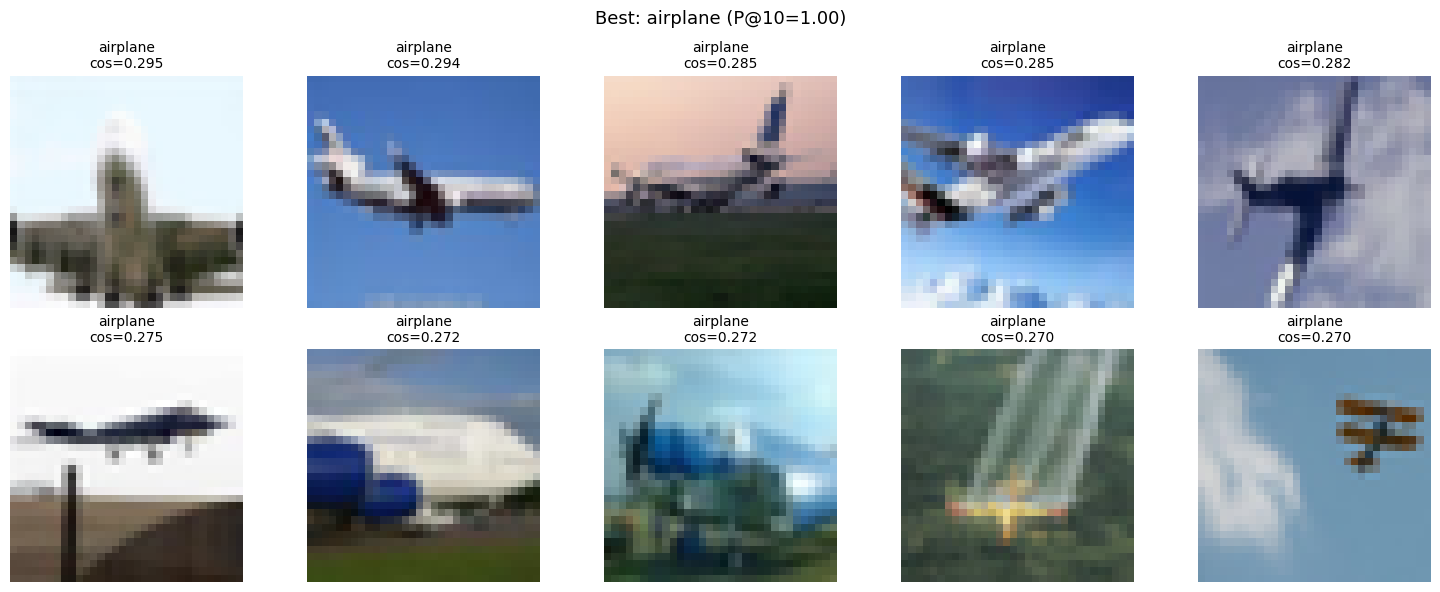

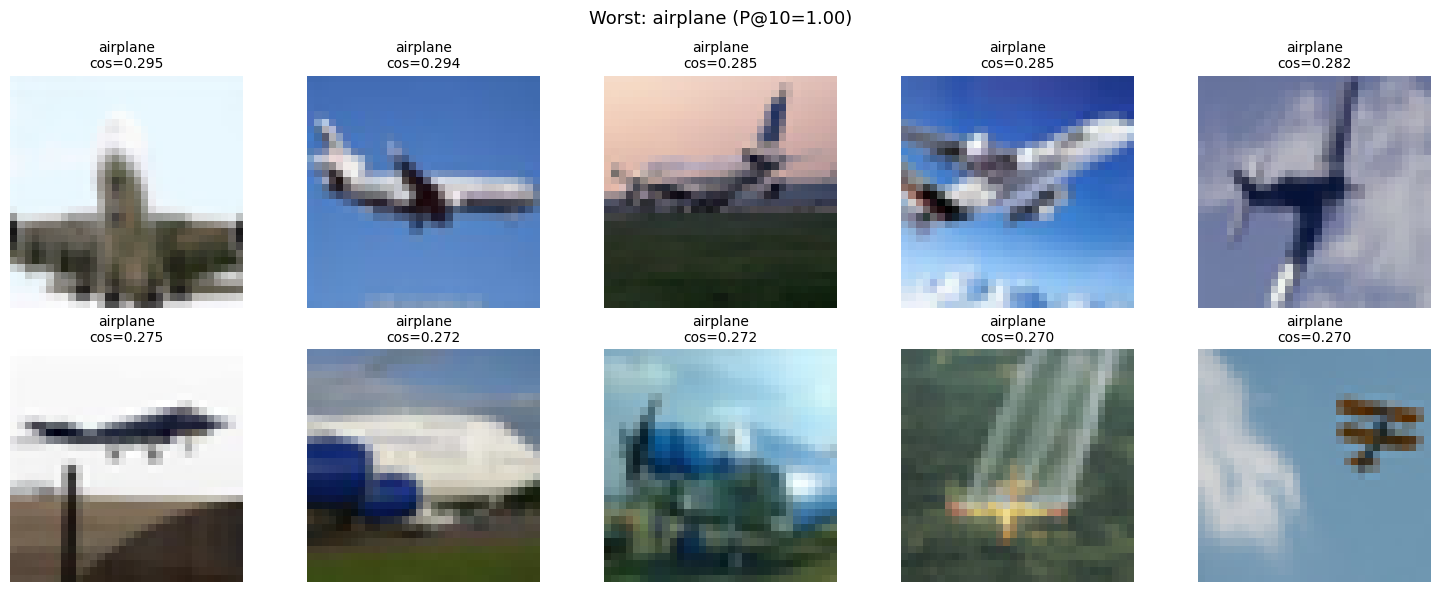

In [ ]:
# tie-breaker: сначала precision, затем AP@10, затем меньший first_relevant_rank
precisions = {c: report[c]["precision@10"] for c in classes}

best_class = max(
    classes,
    key=lambda c: (report[c]["precision@10"], report[c]["ap@10"], -report[c]["first_relevant_rank"])
)
worst_class = min(
    classes,
    key=lambda c: (report[c]["precision@10"], report[c]["ap@10"], report[c]["first_relevant_rank"])
)


def class_top10(class_name):
    tokens = tokenizer([f"a photo of a {class_name}"]).to(DEVICE)
    with torch.no_grad():
        text_feat = model.encode_text(tokens)
        text_feat = text_feat / text_feat.norm(dim=-1, keepdim=True)

    sims = (test_embeddings @ text_feat.cpu().T).squeeze()
    top10 = torch.argsort(sims, descending=True)[:10].numpy()

    return (
        top10.tolist(),
        [int(test_indices[i]) for i in top10],
        test_labels[top10].tolist(),
        [float(sims[i]) for i in top10],
    )


best_pos, best_idx, best_lbls, best_cos = class_top10(best_class)
worst_pos, worst_idx, worst_lbls, worst_cos = class_top10(worst_class)

search_examples = {
    "best_class": best_class,
    "best_precision": float(precisions[best_class]),
    "best_ap10": float(report[best_class]["ap@10"]),
    "best_first_rank": int(report[best_class]["first_relevant_rank"]),
    "best_top10_positions": best_pos,
    "best_top10_test_indices": best_idx,
    "best_top10_labels": best_lbls,
    "best_top10_cosine": best_cos,
    "worst_class": worst_class,
    "worst_precision": float(precisions[worst_class]),
    "worst_ap10": float(report[worst_class]["ap@10"]),
    "worst_first_rank": int(report[worst_class]["first_relevant_rank"]),
    "worst_top10_positions": worst_pos,
    "worst_top10_test_indices": worst_idx,
    "worst_top10_labels": worst_lbls,
    "worst_top10_cosine": worst_cos,
    "note": "При P@10=1.0 для всех классов выбор best/worst сделан по AP@10 и first_relevant_rank",
}

with open(ARTIFACTS / "search_examples.json", "w") as f:
    json.dump(search_examples, f, indent=2)

print(f"Best : {best_class:12s} (P@10={precisions[best_class]:.3f}, "
      f"AP@10={report[best_class]['ap@10']:.3f}, first_rank={report[best_class]['first_relevant_rank']})")
print(f"Worst: {worst_class:12s} (P@10={precisions[worst_class]:.3f}, "
      f"AP@10={report[worst_class]['ap@10']:.3f}, first_rank={report[worst_class]['first_relevant_rank']})")

# выводим коллаж для лучшего класса
show_top10(
    search_examples["best_top10_test_indices"],
    search_examples["best_top10_labels"],
    search_examples["best_top10_cosine"],
    title=f'Best: {search_examples["best_class"]} (P@10={search_examples["best_precision"]:.2f})',
    fname="best_class_top10.png",
)

# выводим коллаж для худшего класса
show_top10(
    search_examples["worst_top10_test_indices"],
    search_examples["worst_top10_labels"],
    search_examples["worst_top10_cosine"],
    title=f'Worst: {search_examples["worst_class"]} (P@10={search_examples["worst_precision"]:.2f})',
    fname="worst_class_top10.png",
)

Попытались найти класс, где поиск работает лучше всего, и класс, где хуже всего. Но так как все метрики идеальные, оба класса оказались одинаковыми airplane

### Поклассовая динамика поиска

*Вес: 1 балл.*

**Постановка.** Средний показатель может скрывать ухудшение поиска для отдельных категорий.

Выполните следующие действия:
1. Повторно вычислите адаптированную precision@10 по каждому классу.
2. Сопоставьте её с исходной precision@10.

**Результат.** retrieval_deltas.json с наблюдаемыми поклассовыми изменениями.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [ ]:
retrieval_deltas = {}
for class_name in classes:
    class_idx = classes.index(class_name)

    # baseline без голов
    tokens = tokenizer([f"a photo of a {class_name}"]).to(DEVICE)
    with torch.no_grad():
        text_feat = model.encode_text(tokens)
        text_feat = text_feat / text_feat.norm(dim=-1, keepdim=True)

    sims_base = (test_embeddings @ text_feat.cpu().T).squeeze()
    p_base, r_base, ap_base, fr_base, _ = ranking_metrics(sims_base, test_labels, class_idx, K=10)

    #adapted с обученными головами
    with torch.no_grad():
        text_proj = text_head(text_feat.to(DEVICE))
        text_proj = text_proj / text_proj.norm(dim=-1, keepdim=True)

    sims_adapt = (adapt_embeds @ text_proj.cpu().T).squeeze()
    p_adapt, r_adapt, ap_adapt, fr_adapt, _ = ranking_metrics(sims_adapt, test_labels, class_idx, K=10)

    retrieval_deltas[class_name] = {
        "baseline_p@10": float(p_base),
        "adapted_p@10": float(p_adapt),
        "delta_p@10": float(p_adapt - p_base),

        "baseline_ap@10": float(ap_base),
        "adapted_ap@10": float(ap_adapt),
        "delta_ap@10": float(ap_adapt - ap_base),

        "baseline_first_rank": fr_base,
        "adapted_first_rank": fr_adapt,
    }

with open(ARTIFACTS / "retrieval_deltas.json", "w") as f:
    json.dump(retrieval_deltas, f, indent=2)

print("P@10 / AP@10 (baseline -> adapted):")
for c in classes:
    d = retrieval_deltas[c]
    print(f"{c:12s}: P@10 {d['baseline_p@10']:.3f}->{d['adapted_p@10']:.3f} ({d['delta_p@10']:+.3f}) | "
          f"AP@10 {d['baseline_ap@10']:.3f}->{d['adapted_ap@10']:.3f} ({d['delta_ap@10']:+.3f})")


P@10 / AP@10 (baseline -> adapted):
airplane    : P@10 1.000->1.000 (+0.000) | AP@10 1.000->1.000 (+0.000)
automobile  : P@10 1.000->1.000 (+0.000) | AP@10 1.000->1.000 (+0.000)
bird        : P@10 1.000->1.000 (+0.000) | AP@10 1.000->1.000 (+0.000)
cat         : P@10 1.000->1.000 (+0.000) | AP@10 1.000->1.000 (+0.000)
deer        : P@10 1.000->1.000 (+0.000) | AP@10 1.000->1.000 (+0.000)
dog         : P@10 1.000->1.000 (+0.000) | AP@10 1.000->1.000 (+0.000)
frog        : P@10 1.000->1.000 (+0.000) | AP@10 1.000->1.000 (+0.000)
horse       : P@10 1.000->1.000 (+0.000) | AP@10 1.000->1.000 (+0.000)
ship        : P@10 1.000->1.000 (+0.000) | AP@10 1.000->1.000 (+0.000)
truck       : P@10 1.000->1.000 (+0.000) | AP@10 1.000->1.000 (+0.000)


Сравнили поиск для каждого класса до и после обучения голов.
все дельты = 0, потому что поиск уже был идеальным (1.0), улучшать нечего

### Творческий бонус: композиционный запрос

*Вес: 1 дополнительный балл.*

**Постановка.** Классовое имя не исчерпывает возможности текстово-визуального поиска.

Выполните следующие действия:
1. Сформулируйте собственный не-классовый запрос и получите top-10.
2. Сохраните коллаж найденных изображений для качественной оценки, не приписывая запросу искусственных меток.

**Результат.** bonus_retrieval.png и bonus_query.json с запросом и индексами.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [ ]:
# Реализуйте это задание по постановке выше.
raise NotImplementedError("Реализуйте это задание в этой ячейке")


## Анализ результатов

Сопоставьте измеренные показатели на отложенных реальных данных. Укажите бюджет, ошибки модели и ограничения сокращённого запуска.

Мы проверили модель на 500 тестовых картинках. Сначала поиск картинок по тексту сработал идеально (точность 100%), потому что CIFAR-10 очень легкий датасет, и модель CLIP и так знает всех котов и самолетов. Зато в обычной классификации (когда даем одну картинку и просим угадать класс) модель сначала ошибалась в 7% случаев (точность 93%). После того как мы дообучили две маленькие проекционные головы, точность выросла до 95.8% (модель стала ошибаться меньше). Ограничение тут только в том, что тест был маленький (всего 500 картинок), поэтому поиск негде было улучшать, он уже был идеальным.